# Phase 1 — Detailed Data Cleaning, Raw Audit, and Locked Splits

## Purpose and final status

This is the authoritative Phase 1 notebook. It defines the business problem, prediction point, source limitations, raw schema, quality evidence, identifiers, leakage policy, and the reproducible 70/15/15 split contract used by every later phase.

## Context & Methods

### 1. Business problem and intended user

The business problem is to predict whether a machine will fail early enough for maintenance teams to act. A useful classifier could help prioritize inspection and maintenance resources, reduce unplanned downtime, and avoid treating every machine state as equally urgent.

The intended primary user is a **maintenance planner or reliability engineer** responsible for triaging equipment observations. The model should support—not replace—engineering judgment. False negatives may allow failures to go unaddressed, while false positives may trigger unnecessary inspections or maintenance.

### 2. Prediction point and available features

The prediction point is assumed to be **immediately after the operating measurements for an observation are available, but before the future failure outcome and its failure-mode diagnosis are known**.

Candidate information available at that point:

- Product quality type: `Type`
- Ambient/operating measurements: air temperature, process temperature, rotational speed, and torque
- Usage/condition measure: tool wear

Excluded from model inputs:

- `UDI` and `Product ID`: identifiers, not physical predictors intended to generalize
- `Machine failure`: the prediction target
- `TWF`, `HDF`, `PWF`, `OSF`, and `RNF`: realized failure-mode labels derived from the same outcome process as the target

This availability assumption must be revalidated before any real deployment because the dataset is not a live production event stream.

### 3. Dataset source and synthetic-data limitation

Source: **UCI Machine Learning Repository — AI4I 2020 Predictive Maintenance Dataset**, loaded from the project copy at `data/raw/ai4i2020.csv`.

The UCI dataset is synthetic and was designed to reflect plausible industrial predictive-maintenance data. Consequently, findings describe this benchmark dataset; they do not establish real-world failure rates, sensor behavior, operational costs, or deployment performance. Any production use would require validation on representative, time-stamped equipment data from the intended environment.

### 4. Imports and configuration

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")

Python: 3.11.9
pandas: 3.0.5


## Data

### 5. Raw-data loading

In [2]:
project_root = Path.cwd()
if not (project_root / "data" / "raw" / "ai4i2020.csv").exists():
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "ai4i2020.csv"
assert data_path.exists(), f"Dataset not found: {data_path.resolve()}"

raw_data = pd.read_csv(data_path)
print(f"Loaded: {data_path.resolve()}")
print(f"Rows: {raw_data.shape[0]:,} | Columns: {raw_data.shape[1]}")

Loaded: data/raw/ai4i2020.csv
Rows: 10,000 | Columns: 14


### 6. Shape, sample, types, and descriptive statistics

In [3]:
print(f"Shape: {raw_data.shape}")
display(raw_data.head())

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


In [4]:
column_profile = pd.DataFrame({
    "dtype": raw_data.dtypes.astype(str),
    "non_null": raw_data.notna().sum(),
    "unique": raw_data.nunique(dropna=False),
})
display(column_profile)

,dtype,non_null,unique
UDI,int64,10000,10000
Product ID,str,10000,10000
Type,str,10000,3
Air temperature [K],float64,10000,93
Process temperature [K],float64,10000,82
Rotational speed [rpm],int64,10000,941
Torque [Nm],float64,10000,577
Tool wear [min],int64,10000,246
Machine failure,int64,10000,2
TWF,int64,10000,2


In [5]:
display(raw_data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,"10,000.000",NaN,NaN,NaN,"5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],"10,000.000",NaN,NaN,NaN,300.005,2.000,295.300,298.300,300.100,301.500,304.500
Process temperature [K],"10,000.000",NaN,NaN,NaN,310.006,1.484,305.700,308.800,310.100,311.100,313.800
Rotational speed [rpm],"10,000.000",NaN,NaN,NaN,"1,538.776",179.284,"1,168.000","1,423.000","1,503.000","1,612.000","2,886.000"
Torque [Nm],"10,000.000",NaN,NaN,NaN,39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool wear [min],"10,000.000",NaN,NaN,NaN,107.951,63.654,0.000,53.000,108.000,162.000,253.000
Machine failure,"10,000.000",NaN,NaN,NaN,0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,"10,000.000",NaN,NaN,NaN,0.005,0.068,0.000,0.000,0.000,0.000,1.000


### 7. Missing values and duplicate checks

In [6]:
missing_summary = (
    raw_data.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda table: 100 * table["missing_count"] / len(raw_data))
)
duplicate_rows = int(raw_data.duplicated().sum())
duplicate_udi = int(raw_data["UDI"].duplicated().sum())
duplicate_product_id = int(raw_data["Product ID"].duplicated().sum())

display(missing_summary)
print(f"Fully duplicated rows: {duplicate_rows:,}")
print(f"Duplicated UDI values: {duplicate_udi:,}")
print(f"Duplicated Product ID values: {duplicate_product_id:,}")

,missing_count,missing_pct
UDI,0,0.000
Product ID,0,0.000
Type,0,0.000
Air temperature [K],0,0.000
Process temperature [K],0,0.000
Rotational speed [rpm],0,0.000
Torque [Nm],0,0.000
Tool wear [min],0,0.000
Machine failure,0,0.000
TWF,0,0.000


Fully duplicated rows: 0
Duplicated UDI values: 0
Duplicated Product ID values: 0


### 8. Initial data dictionary

In [7]:
data_dictionary = pd.DataFrame([
    ("UDI", "Identifier", "Unique row identifier", "Exclude"),
    ("Product ID", "Identifier", "Product identifier containing type/serial information", "Exclude"),
    ("Type", "Categorical feature", "Product quality variant: L, M, or H", "Candidate feature"),
    ("Air temperature [K]", "Numeric feature", "Air temperature in kelvin", "Candidate feature"),
    ("Process temperature [K]", "Numeric feature", "Process temperature in kelvin", "Candidate feature"),
    ("Rotational speed [rpm]", "Numeric feature", "Rotational speed in revolutions per minute", "Candidate feature"),
    ("Torque [Nm]", "Numeric feature", "Torque in newton-metres", "Candidate feature"),
    ("Tool wear [min]", "Numeric feature", "Accumulated tool-wear time in minutes", "Candidate feature"),
    ("Machine failure", "Binary target", "Whether a machine failure occurred", "Target"),
    ("TWF", "Leakage label", "Tool-wear failure flag", "Exclude"),
    ("HDF", "Leakage label", "Heat-dissipation failure flag", "Exclude"),
    ("PWF", "Leakage label", "Power failure flag", "Exclude"),
    ("OSF", "Leakage label", "Overstrain failure flag", "Exclude"),
    ("RNF", "Leakage label", "Random failure flag", "Exclude"),
], columns=["column", "role", "description", "modelling_status"])

display(data_dictionary)

,column,role,description,modelling_status
0,UDI,Identifier,Unique row identifier,Exclude
1,Product ID,Identifier,Product identifier containing type/serial info...,Exclude
2,Type,Categorical feature,"Product quality variant: L, M, or H",Candidate feature
3,Air temperature [K],Numeric feature,Air temperature in kelvin,Candidate feature
4,Process temperature [K],Numeric feature,Process temperature in kelvin,Candidate feature
5,Rotational speed [rpm],Numeric feature,Rotational speed in revolutions per minute,Candidate feature
6,Torque [Nm],Numeric feature,Torque in newton-metres,Candidate feature
7,Tool wear [min],Numeric feature,Accumulated tool-wear time in minutes,Candidate feature
8,Machine failure,Binary target,Whether a machine failure occurred,Target
9,TWF,Leakage label,Tool-wear failure flag,Exclude


## Results

### 9. Target distribution and class-balance visualization

In [8]:
target_counts = raw_data["Machine failure"].value_counts().sort_index()
target_distribution = pd.DataFrame({
    "class_label": ["No failure", "Failure"],
    "count": target_counts.reindex([0, 1], fill_value=0).values,
})
target_distribution["percentage"] = (
    100 * target_distribution["count"] / target_distribution["count"].sum()
)
display(target_distribution)

,class_label,count,percentage
0,No failure,9661,96.610
1,Failure,339,3.390


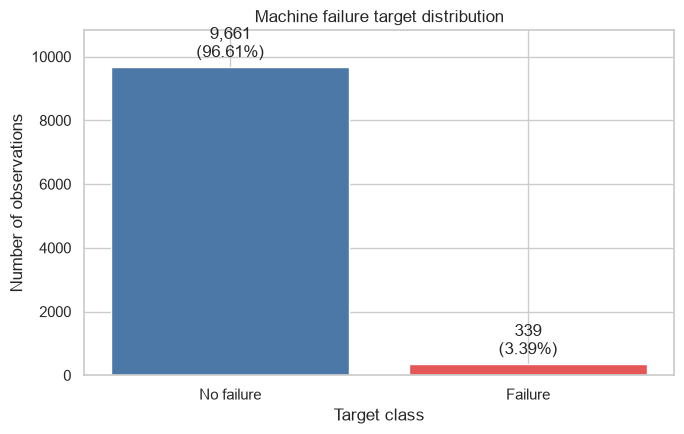

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    target_distribution["class_label"],
    target_distribution["count"],
    color=["#4C78A8", "#E45756"],
)
ax.set(
    title="Machine failure target distribution",
    xlabel="Target class",
    ylabel="Number of observations",
)
ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            target_distribution["count"], target_distribution["percentage"]
        )
    ],
    padding=4,
)
ax.set_ylim(0, target_distribution["count"].max() * 1.12)
plt.tight_layout()
plt.show()

**Interpretation:** The positive class is rare relative to the negative class. In later phases, an accuracy-only evaluation would be misleading; recall, precision, PR-AUC, confusion matrices, threshold selection, and cost trade-offs should be considered. This observation does not select a model or sampling method.

### 10. Leakage assessment

In [10]:
identifier_columns = ["UDI", "Product ID"]
target_column = "Machine failure"
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]
candidate_feature_columns = [
    column
    for column in raw_data.columns
    if column not in identifier_columns + [target_column] + leakage_columns
]

feature_policy = pd.DataFrame({
    "group": ["Identifiers", "Target", "Target-derived failure modes", "Candidate predictors"],
    "columns": [
        ", ".join(identifier_columns),
        target_column,
        ", ".join(leakage_columns),
        ", ".join(candidate_feature_columns),
    ],
    "action": [
        "Exclude from modelling",
        "Predict; never include in X",
        "Exclude from modelling as leakage",
        "Eligible for later modelling after validation",
    ],
})
display(feature_policy)

,group,columns,action
0,Identifiers,"UDI, Product ID",Exclude from modelling
1,Target,Machine failure,Predict; never include in X
2,Target-derived failure modes,"TWF, HDF, PWF, OSF, RNF",Exclude from modelling as leakage
3,Candidate predictors,"Type, Air temperature [K], Process temperature...",Eligible for later modelling after validation


In [11]:
failure_mode_any = raw_data[leakage_columns].max(axis=1)
failure_mode_count = raw_data[leakage_columns].sum(axis=1)

leakage_crosscheck = pd.crosstab(
    raw_data[target_column],
    failure_mode_any,
    rownames=[target_column],
    colnames=["Any failure-mode flag"],
    margins=True,
)
mismatch_mask = raw_data[target_column].ne(failure_mode_any)

display(leakage_crosscheck)
print(f"Rows where target differs from OR of failure-mode flags: {mismatch_mask.sum():,}")
print(f"Rows with multiple active failure-mode flags: {(failure_mode_count > 1).sum():,}")

Any failure-mode flag,0,1,All
Machine failure,,,
0,9643,18,9661
1,9,330,339
All,9652,348,10000


Rows where target differs from OR of failure-mode flags: 27
Rows with multiple active failure-mode flags: 24


The five failure-mode flags describe the realized mechanism associated with failure and are not ordinary sensor inputs. Their close structural relationship to `Machine failure` means including them would allow the model to infer the answer from outcome information that would not be available at the stated prediction point. They are therefore excluded regardless of whether edge-case inconsistencies exist between the aggregate target and individual flags.

The identifiers are also excluded: `UDI` is a row key, and `Product ID` is a product identifier whose serial-like component could encourage memorization or dataset-order artifacts rather than transferable physical relationships.

## Takeaways

- The raw file loaded successfully and is structurally complete: 10,000 rows, 14 columns, no missing values, and no full-row duplicates.
- The target is materially imbalanced: 339 failures (3.39%) versus 9,661 non-failures (96.61%).
- The approved future predictor set is limited to `Type`, the four operating measurements, and `Tool wear [min]`, subject to later validation.
- `UDI` and `Product ID` are identifiers; `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` are target-derived leakage. All seven columns are excluded from modelling.
- Synthetic benchmark results must not be presented as estimates of a real factory's failure risk or operational benefit.

### Phase boundary

Phase 1 is complete. No preprocessing pipeline, data split, feature engineering, resampling, model fitting, or model evaluation is performed in this notebook.

# Governed cleaning decisions and locked splits

## Scope

In [12]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'data/raw/ai4i2020.csv').exists():root=root.parent
TARGET='Machine failure'; BASE=['Type','Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']; IDS=['UDI','Product ID']; LEAK=['TWF','HDF','PWF','OSF','RNF']
raw=pd.read_csv(root/'data/raw/ai4i2020.csv'); print(raw.shape); display(raw.head())

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


## Schema and memory audit

In [13]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),'missing_pct':100*raw.isna().mean(),'unique':raw.nunique()})); print(raw.memory_usage(deep=True).sum()/1e6,'MB')

,dtype,missing,missing_pct,unique
UDI,int64,0,0.000,10000
Product ID,str,0,0.000,10000
Type,str,0,0.000,3
Air temperature [K],float64,0,0.000,93
Process temperature [K],float64,0,0.000,82
Rotational speed [rpm],int64,0,0.000,941
Torque [Nm],float64,0,0.000,577
Tool wear [min],int64,0,0.000,246
Machine failure,int64,0,0.000,2
TWF,int64,0,0.000,2


2.170132 MB


## Duplicates and identifiers

In [14]:
print('duplicates',raw.duplicated().sum(),'UDI duplicates',raw.UDI.duplicated().sum(),'Product ID duplicates',raw['Product ID'].duplicated().sum())

duplicates 0 UDI duplicates 0 Product ID duplicates 0


## Category normalization check

In [15]:
display(raw.Type.value_counts(dropna=False)); print(sorted(raw.Type.astype(str).unique()))

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

['H', 'L', 'M']


## Invalid ranges

In [16]:
display(pd.Series({'rpm <= 0':(raw['Rotational speed [rpm]']<=0).sum(),'torque < 0':(raw['Torque [Nm]']<0).sum(),'wear < 0':(raw['Tool wear [min]']<0).sum(),'process <= air':(raw['Process temperature [K]']<=raw['Air temperature [K]']).sum(),'invalid target':(~raw[TARGET].isin([0,1])).sum()}))

rpm <= 0          0
torque < 0        0
wear < 0          0
process <= air    0
invalid target    0
dtype: int64

## Cleaning decision log

In [17]:
log=pd.DataFrame([('Missing values','None','No treatment'),('Exact duplicates','None','No removal'),('Ranges','No objective errors','Retain extremes'),('Type','L/M/H consistent','No normalization'),('Identifiers','Valid keys','Exclude from model'),('Failure modes','Post-outcome labels','Exclude as leakage')],columns=['check','evidence','decision']); display(log)

,check,evidence,decision
0,Missing values,None,No treatment
1,Exact duplicates,None,No removal
2,Ranges,No objective errors,Retain extremes
3,Type,L/M/H consistent,No normalization
4,Identifiers,Valid keys,Exclude from model
5,Failure modes,Post-outcome labels,Exclude as leakage


## Lock 70/15/15 split

In [18]:
from sklearn.model_selection import train_test_split
dev,test=train_test_split(raw,test_size=.15,stratify=raw[TARGET],random_state=2026)
train,val=train_test_split(dev,test_size=.15/.85,stratify=dev[TARGET],random_state=2026)
out=root/'data/governed'; out.mkdir(parents=True,exist_ok=True)
for name,d in [('train',train),('validation',val),('test',test)]: d.to_csv(out/f'{name}.csv',index=False)
summary=pd.DataFrame({n:{'rows':len(d),'failures':int(d[TARGET].sum()),'rate':d[TARGET].mean()} for n,d in [('train',train),('validation',val),('test',test)]}).T; display(summary)

,rows,failures,rate
train,"7,000.000",237.000,0.034
validation,"1,500.000",51.000,0.034
test,"1,500.000",51.000,0.034


## Save split contract

In [19]:
contract={'random_state':2026,'ratios':[.70,.15,.15],'stratified':True,'target':TARGET,'positive_class':1,'prediction_point':'after current measurements, before failure outcome','test_policy':'sealed until pipeline, hyperparameters, features, and threshold are frozen','historical_caveat':'Earlier project iterations inspected this dataset; this is a governance reset, not a truly external test.'}; (out/'split_contract.json').write_text(json.dumps(contract,indent=2)); display(contract)

{'random_state': 2026,
 'ratios': [0.7, 0.15, 0.15],
 'stratified': True,
 'target': 'Machine failure',
 'positive_class': 1,
 'prediction_point': 'after current measurements, before failure outcome',
 'test_policy': 'sealed until pipeline, hyperparameters, features, and threshold are frozen',
 'historical_caveat': 'Earlier project iterations inspected this dataset; this is a governance reset, not a truly external test.'}